
## 01MIAR - Actividad Video Valencia Pollution

## NumPy y Pandas

### Objetivos:
- Aplicar diferentes técnicas de tratamiento de estructuras numéricas con Numpy y datos estructurados con Pandas.

### Instrucciones:
- Mantener una estructura limpia, comentando código y secuenciando los apartados con el código correspondiente que resuelva la actividad.
- Como criterio de evaluación se tendrá en cuenta el resultado, la consecución del mismo, estilo, comentarios y adecuación. Siempre será tenido en cuenta cualquier detalle técnico avanzado o no visto en clase relacionado con el tema (explicar el porqué y usabilidad).
- No está permitido compartir los resultados ni el código en ninguno de los foros.
- Revisar los temas así como las sesiones sobre Numpy y Pandas para aplicar dichos contenidos.
- Proponer las respuestas en las celdas a dicho efecto en cada punto, si se necesitan más celdas añadirlas en su sitio correspondiente
- Mostrar de manera clara la respuesta a las preguntas, mediante código

### Entrega:
- Este mismo notebook con las respuetas

### Evaluación
- Esta actividad corresponde con el 10% de la nota final de la asignatura.

### Fecha Realización
- Convocatoria 1 - 30/05/2026 00:00 - 31/05/2026 08:00 (Hora España)

#### Descripción
El conjunto de datos "valencia_pollution_dataset.csv" (fichero disponible adjunto a la actividad) proviene de una descarga de datos del servicio web del ayuntamiento de la ciudad de Valencia de datos abiertos.

Cada estación realiza una serie de mediciones acerca de la calidad del aire, y de ciertas sustancias que se consideran importantes para analizar la contaminación atmosférica en la ciudad.

#### Columnas para trabajar:
- objectid: id de la estación
- nombre: nombre de la estación
- dirección: dirección de la estación
- tipozona: tipo de la zona, urbana o sub urbana
- parámetros: parámetroe medidos
- mediciones: fichero de mediciones
- tipoemisio: tráfico o fondo
- so2: niveles de dióxido de azufre
- no2: niveles de dióxido de nitrogeno
- o3: niveles de ozono
- co: niveles de monóxido de carbono
- pm10: niveles de partículas en suspensión hasta 10um
- pm25: niveles de partículas en suspensión hasta 2,5um
- fecha_carg: timestamp de la actualización de los datos
- calidad_am: estimación de la calidad del aire
- fiwareid: Identificador sensor
- lon: longitud en coordenadas geográficas
- lat: latitud en coordenadas geográficas

In [152]:
# imports para el analisis
# Lucas Tamara Trejo actividad del video contaminación del aire 30/05/2026
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


## 01
- Carga de datos de csv (valencia_pollution_dataset.csv) en un DataFrame.
- Mostrar 6 fillas aleatorias
- Mostrar la cantidad de valores nulos por columna

In [153]:
# cargo el csv 
df = pd.read_csv("valencia_pollution_dataset.csv", encoding="utf-8-sig")

# 6 filas random del dataset para ver como vienen los datos
print("sample aleatorio:")
display(df.sample(6))

# valor añadido: cantidad y % de nulos por columna usando numpy
# np.round para redondear el porcentaje - solo muestra columnas con nulos
nulos_count = df.isnull().sum()
nulos_pct   = np.round((nulos_count / len(df)) * 100, 1)
resumen_nulos = pd.DataFrame({"nulos": nulos_count, "% nulos": nulos_pct})
print("valores nulos por columna:")
display(resumen_nulos[resumen_nulos["nulos"] > 0])


sample aleatorio:


,objectid,nombre,direccion,tipozona,parametros,mediciones,so2,no2,o3,co,pm10,pm25,tipoemisio,fecha_carg,calidad_am,fiwareid,lon,lat
29,14,Boulevar Sur,BULEVARD SUD,Urbana,"Dióxido de azufre (SO2),Ozono,Óxidos de nitróg...",http://mapas.valencia.es/WebsMunicipales/uploa...,0.0,10.0,87.0,NaN,NaN,NaN,Tráfico,2026-05-28,Razonablemente Buena,A02_BULEVARDSUD_60m,-0.396338,39.450396
32,19,Centro,VALÈNCIA CENTRE,Urbana,"Óxidos de nitrógeno totales (NOx),Monóxido de ...",https://mapas.valencia.es/WebsMunicipales/uplo...,NaN,12.0,NaN,NaN,27.0,11.0,Tráfico,2026-05-28,Razonablemente Buena,A07_VALENCIACENTRE_60m,-0.376398,39.470548
103,12,Dr. Lluch,DR.LLUCH,Urbana,"Óxidos de nitrógeno totales (NOx),Monóxido de ...",NaN,NaN,36.0,NaN,NaN,28.0,11.0,Tráfico,2026-05-28 06:00:00,Razonablemente Buena,A08_DR_LLUCH_60m,-0.328289,39.466685
74,17,Universidad Politécnica,POLITÈCNIC,Suburbana,"Dióxido de azufre (SO2),Ozono,Óxidos de nitróg...",http://mapas.valencia.es/WebsMunicipales/uploa...,1.0,20.0,47.0,NaN,14.0,8.0,Fondo,2026-05-28 04:00:00,Buena,A05_POLITECNIC_60m,-0.337401,39.479644
85,17,Universidad Politécnica,POLITÈCNIC,Suburbana,"Dióxido de azufre (SO2),Ozono,Óxidos de nitróg...",http://mapas.valencia.es/WebsMunicipales/uploa...,2.0,29.0,37.0,NaN,14.0,9.0,Fondo,2026-05-28 05:00:00,Buena,A05_POLITECNIC_60m,-0.337401,39.479644
224,22,Patraix,PATRAIX,Urbana,"Óxidos de nitrógeno totales (NOx),Monóxido de ...",NaN,NaN,53.0,NaN,NaN,32.0,14.0,Tráfico,2026-05-28 22:00:00,Razonablemente Buena,A11_PATRAIX_60m,-0.401411,39.459189


valores nulos por columna:


,nulos,% nulos
parametros,26,9.1
mediciones,104,36.4
so2,130,45.5
o3,130,45.5
co,208,72.7
pm10,52,18.2
pm25,52,18.2


## 02
- ¿Cuantas estaciones diferentes hay?
- ¿Cuantas estaciones cuentan con un sensor de monóxido de carbono (co)?
- ¿Cuantas estaciones cuentan con un sensor ozono (o3)?

In [154]:
sensores = ["co", "o3", "no2", "so2", "pm10", "pm25"]

# conteo de estaciones unicas y por sensor - filtro notna para detectar que estaciones tienen cada sensor
resumen_02 = pd.DataFrame({
    "pregunta": ["estaciones diferentes", "con sensor CO", "con sensor O3"],
    "cantidad": [
        df["nombre"].nunique(),
        df[df["co"].notna()]["nombre"].nunique(),
        df[df["o3"].notna()]["nombre"].nunique()
    ]
}).set_index("pregunta")

display(resumen_02)


,cantidad
pregunta,
estaciones diferentes,11
con sensor CO,3
con sensor O3,6


## 03
 - Para cada sensor (co, o3, no2, so2, pm10 y pm25) indicar la estación con la media de medición más alta.

In [155]:
sensores = ["co", "o3", "no2", "so2", "pm10", "pm25"]

# media por estacion - NaN ignorados automaticamente con groupby
media_por_estacion = df.groupby("nombre")[sensores].mean().round(2)

# construyo tabla con estacion de media mas alta por sensor - manejo empates
filas = []
for sensor in sensores:
    col       = media_por_estacion[sensor]
    val_max   = col.max()
    empatadas = col[col == val_max].index.tolist()
    filas.append({
        "sensor"  : sensor.upper(),
        "estacion": ", ".join(empatadas),
        "media"   : val_max
    })

resumen_03 = pd.DataFrame(filas).set_index("sensor")
display(resumen_03)


,estacion,media
sensor,,
CO,"Francia, Molí del Sol, Pista de Silla",0.00
O3,Viveros,78.92
NO2,Patraix,53.00
SO2,Molí del Sol,6.12
PM10,Olivereta,33.77
PM25,Olivereta,15.00


## 04
Mostrar en dos gráficos de barras la media de las mediciones de dióxido de nitrógeno (no2) de cada estación agrupando por el tipo de zona (tipozona). Cada gráfico debe mostrar un tipo de emisión distinto (tipoemision).

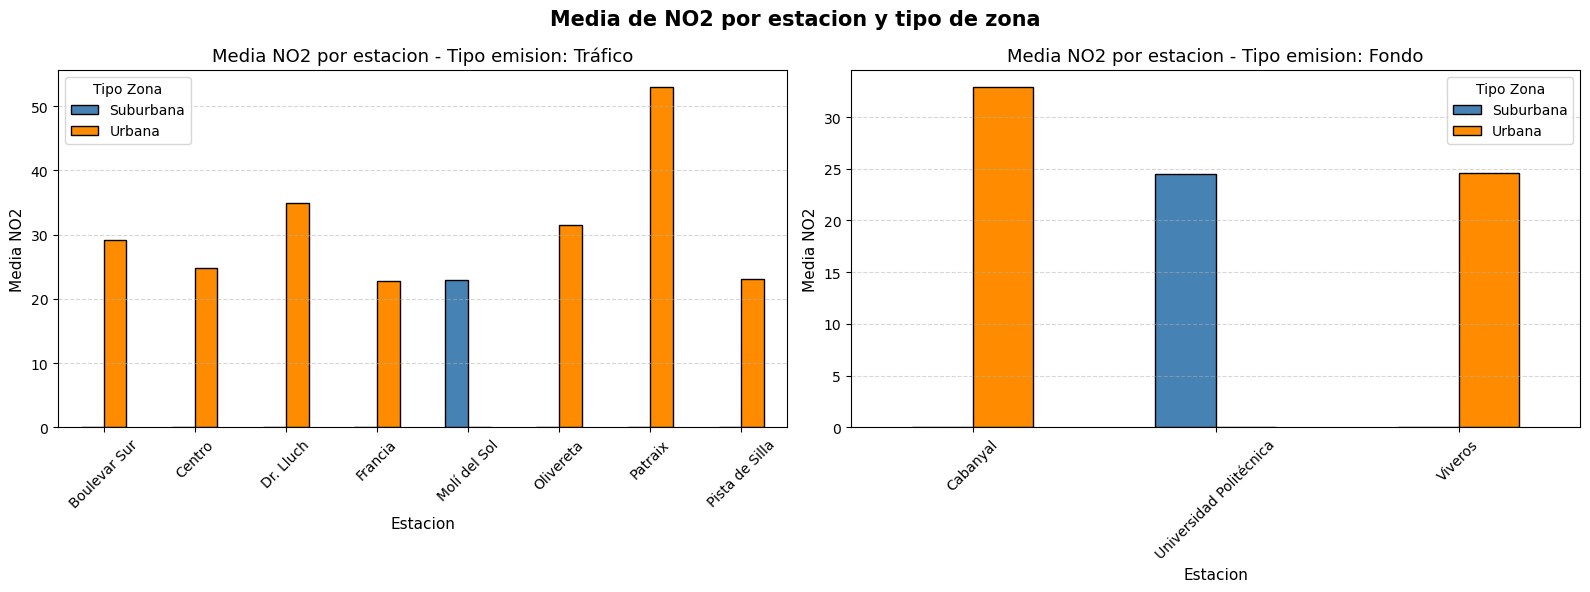

In [156]:
# dos graficos, uno por cada tipo de emision (Trafico / Fondo)
tipos_emision = df["tipoemisio"].unique()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, tipo in zip(axes, tipos_emision):
    # filtro por tipo de emision y calculo media de NO2 por estacion y tipozona
    df_tipo = df[df["tipoemisio"] == tipo]
    media   = df_tipo.groupby(["nombre", "tipozona"])["no2"].mean().round(2).reset_index()

    # pivot: tipozona como columnas para barras agrupadas (Urbana / Suburbana)
    pivot = media.pivot(index="nombre", columns="tipozona", values="no2")
    pivot.plot(kind="bar", ax=ax, color=["steelblue", "darkorange"], edgecolor="black")

    ax.set_title("Media NO2 por estacion - Tipo emision: " + tipo, fontsize=13)
    ax.set_xlabel("Estacion", fontsize=11)
    ax.set_ylabel("Media NO2", fontsize=11)
    ax.tick_params(axis="x", rotation=45)
    ax.legend(title="Tipo Zona")
    ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.suptitle("Media de NO2 por estacion y tipo de zona", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()


## 05
Eres un analista de datos y quieres evaluar visualmente si existe una relación entre las mediciones de los sensores (co, o3, no2, so2, pm10 y pm25) y la calidad del aire (calidad_ambiental). ¿Qué visualización propones y porqué?

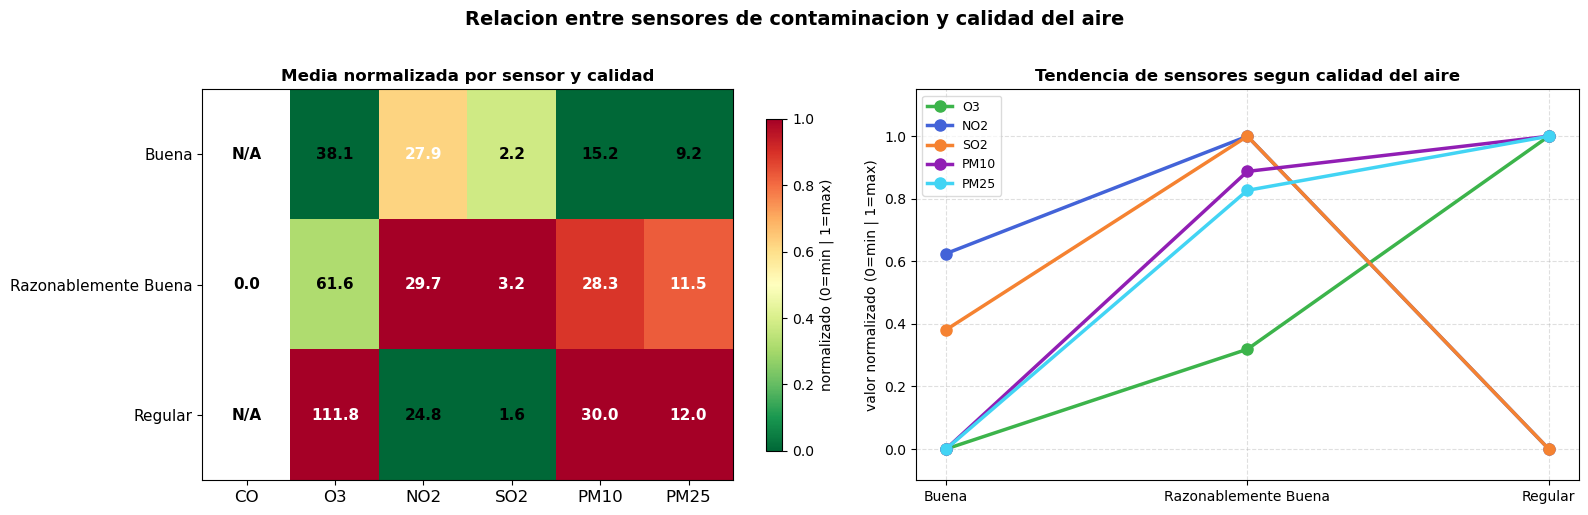

In [157]:
sensores  = ["co", "o3", "no2", "so2", "pm10", "pm25"]

# orden calidad_am derivado del csv usando o3
orden_cal = df.groupby("calidad_am")["o3"].mean().sort_values().index.tolist()

# media por calidad_am
media = df.groupby("calidad_am")[sensores].mean().reindex(orden_cal)

# normalizo 0-1 por columna - safe: si rango=0 (ej. CO) deja NaN en vez de dividir por cero
rango      = media.max() - media.min()
media_norm = (media - media.min()) / rango.replace(0, np.nan)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# --- viz 1: heatmap ---
im = ax1.imshow(media_norm.values, cmap="RdYlGn_r", aspect="auto", vmin=0, vmax=1)
ax1.set_xticks(range(len(sensores)))
ax1.set_xticklabels([s.upper() for s in sensores], fontsize=12)
ax1.set_yticks(range(len(orden_cal)))
ax1.set_yticklabels(orden_cal, fontsize=11)
ax1.set_title("Media normalizada por sensor y calidad", fontsize=12, fontweight="bold")
plt.colorbar(im, ax=ax1, label="normalizado (0=min | 1=max)", shrink=0.85)
for i in range(len(orden_cal)):
    for j in range(len(sensores)):
        val      = media.values[i, j]
        val_norm = media_norm.values[i, j]
        txt      = f"{val:.1f}" if not np.isnan(val) else "N/A"
        ctxt     = "white" if not np.isnan(val_norm) and val_norm > 0.55 else "black"
        ax1.text(j, i, txt, ha="center", va="center", fontsize=11, fontweight="bold", color=ctxt)

# --- viz 2: trend lines ---
# pendiente positiva = sensor sube cuando calidad empeora = relacion directa
colores_linea = ["#e6194b", "#3cb44b", "#4363d8", "#f58231", "#911eb4", "#42d4f4"]
x = np.arange(len(orden_cal))
for sensor, color in zip(sensores, colores_linea):
    valores = media_norm[sensor].values
    mascara = ~np.isnan(valores)
    if mascara.sum() >= 2:
        ax2.plot(x[mascara], valores[mascara], marker="o", linewidth=2.5,
                 markersize=8, color=color, label=sensor.upper())
ax2.set_xticks(x)
ax2.set_xticklabels(orden_cal, fontsize=10)
ax2.set_ylabel("valor normalizado (0=min | 1=max)", fontsize=10)
ax2.set_title("Tendencia de sensores segun calidad del aire", fontsize=12, fontweight="bold")
ax2.legend(loc="upper left", fontsize=9, framealpha=0.7)
ax2.grid(linestyle="--", alpha=0.4)
ax2.set_ylim(-0.1, 1.15)

fig.suptitle("Relacion entre sensores de contaminacion y calidad del aire",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


#### Razonamiento

**Visualizacion: Heatmap normalizado + Trend lines**

Dos viz complementarias porque cada una responde una pregunta distinta.

**Heatmap** — responde: que sensor tiene nivel alto/bajo en cada calidad del aire.
Normalizo 0-1 para poder comparar sensores con escalas distintas (O3 en ug/m3, CO en mg/m3).
Sin normalizar no puedes comparar visualmente — el rango de O3 aplasta al de SO2.
Verde = nivel bajo, Rojo = nivel alto en esa categoria.

**Trend lines** — responden: existe relacion directa o no?
Pendiente positiva de Buena a Regular = sensor sube cuando el aire empeora.
Pendiente plana o inversa = sin relacion clara.

Lo que muestran los datos del csv:
- O3: pendiente mas pronunciada (38 -> 62 -> 112). Relacion directa fuerte.
- PM10 y PM25: misma tendencia positiva. Relacion directa confirmada.
- NO2 y SO2: suben en Razon. Buena pero bajan en Regular. Sin relacion clara.
  Posiblemente porque Regular solo tiene 6 muestras en el csv.
- CO: todos los valores son 0.0 en el csv (78 lecturas). Rango cero,
  no se puede normalizar ni graficar tendencia.

Limitacion: Regular tiene muy pocas muestras (pm10=1, pm25=1).
Esos puntos hay que interpretarlos con cautela.

Conclusion: O3, PM10 y PM25 son los sensores con relacion directa
con la calidad del aire. O3 es el mas predictivo.
